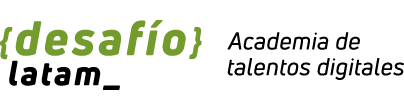

# <font color = 'green'>Redes neuronales </font>




In [2]:
pip install tensorflow

   ---------------------------------------- 0.0/390.3 MB ? eta -:--:--
   ---------------------------------------- 1.6/390.3 MB 9.3 MB/s eta 0:00:42
   ---------------------------------------- 2.1/390.3 MB 8.4 MB/s eta 0:00:47
   ---------------------------------------- 3.4/390.3 MB 5.9 MB/s eta 0:01:06
    --------------------------------------- 5.2/390.3 MB 6.5 MB/s eta 0:01:00
    --------------------------------------- 7.1/390.3 MB 6.9 MB/s eta 0:00:56
    --------------------------------------- 8.9/390.3 MB 7.3 MB/s eta 0:00:53
   - -------------------------------------- 10.7/390.3 MB 7.5 MB/s eta 0:00:51
   - -------------------------------------- 12.6/390.3 MB 7.7 MB/s eta 0:00:49
   - -------------------------------------- 14.7/390.3 MB 8.0 MB/s eta 0:00:47
   - -------------------------------------- 16.5/390.3 MB 8.1 MB/s eta 0:00:47
   - -------------------------------------- 18.1/390.3 MB 8.1 MB/s eta 0:00:46
   -- ------------------------------------- 19.9/390.3 MB 8.1 MB/s

In [4]:
import tensorflow as tf
print(tf.__version__)

2.18.0


In [5]:
pip install keras

Note: you may need to restart the kernel to use updated packages.


 ## <font color = 'green'>Entrenamiento de un perceptrón</font>


Intentaremos predecir la edad de una persona que cuente con rut (en rigor, run) el cual representa un número único de identificación en Chile.

### <font color = 'green'>Carga de bibliotecas</font>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime
from util_plot import plot_region_classifier

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, r2_score, mean_squared_error
from sklearn.preprocessing import StandardScaler
from sklearn.datasets import make_blobs, make_circles

import tensorflow as tf
import keras
from keras.models import Sequential
from keras.layers import Dense
from keras.optimizers import SGD # Gradiente Descendente estocástico

plt.style.use('ggplot')

# backend usado por keras
print(f'Backend usado por keras: {keras.backend.backend()}')

Backend usado por keras: tensorflow


### <font color = 'green'>Carga de datos</font>

In [3]:
df = pd.read_csv('rut.csv', sep=';', encoding='utf-8')
df.head()

,fechaNacimiento,rut
0,1935-06-10,4075947-6
1,1935-07-09,3822071-3
2,1935-10-01,3583168-1
3,1937-04-19,4066560-9
4,1937-07-30,3690687-1


### <font color = 'green'>Transformación</font>
- Calculamos la edad en días desde la fecha de nacimiento con respecto al día de hoy.
- Se usa como variable regresora el RUT sin considerar el guión ni su digito verificador

In [5]:
# Aquí se convierte la columna 'fechaNacimiento' de df a un tipo de dato de fecha (datetime), 
# asumiendo que las fechas están en formato 'Año-Mes-Día' (%Y-%m-%d).

df['fechaNacimiento'] = pd.to_datetime(df['fechaNacimiento'], format='%Y-%m-%d')

# obtiene la fecha actual (el día de hoy) y la guarda en la variable fhoy.
fhoy = pd.to_datetime('today')

# Calcula la edad en días
df['edad_dias'] = (fhoy - df['fechaNacimiento']).apply(lambda x: x.days)

# elimina los últimos dos caracteres y luego, convierte el resultado a un tipo de dato entero y lo almacena en una nueva columna llamada 'rut2'.
df['rut2'] = df['rut'].str[:-2].astype('int')
df.tail()

,fechaNacimiento,rut,edad_dias,rut2
1170,1998-02-16,19725671-0,9858,19725671
1171,1998-03-11,19512202-4,9835,19512202
1172,1998-09-23,19964601-K,9639,19964601
1173,1998-10-30,19964664-8,9602,19964664
1174,1999-02-18,19964817-9,9491,19964817


Estandarizaremos la variable regresora **rut2**

El código estandariza las columnas 'rut2' y 'edad_dias' (las convierte para que tengan media 0 y desviación estándar 1), y luego selecciona solo los valores escalados de la columna 'rut2' (los primeros elementos de cada fila) y los almacena en la variable X_ss.

ss = StandardScaler()

X_ss = ss.fit_transform(df[['rut2', 'edad_dias']])[:,0]

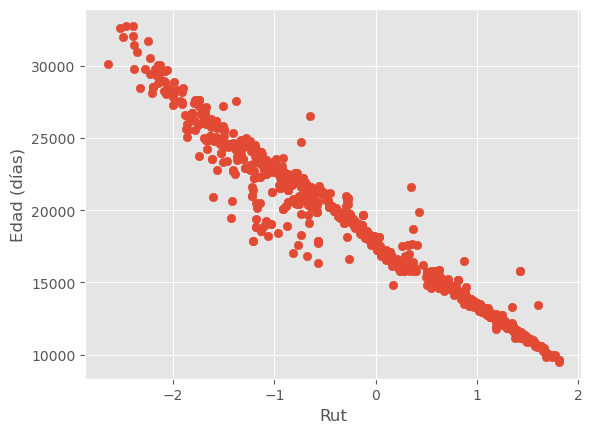

In [7]:
ss = StandardScaler()
X_ss = ss.fit_transform(df[['rut2', 'edad_dias']])[:,0]
y = df['edad_dias']

plt.scatter(X_ss, df['edad_dias'])
plt.xlabel('Rut')
plt.ylabel('Edad (días)');

Se devide el conjunto de datos en entrenamiento y test

In [9]:
X_train, X_test, y_train, y_test = train_test_split(X_ss, y, test_size=.33, random_state=23)

### <font color = 'green'>Implementación</font>

In [11]:
# creamos un modelo Secuencial
model_ann1 = Sequential()

# agregamos la capa de entrada
# shape = 1, -> solamente una capa de entrada
model_ann1.add(keras.Input(shape=(1,)))

# agregamos el perceptrón considerando un Bias
# y una función de activación lineal
model_ann1.add(
    Dense(
        units=1,
        activation='linear',
        use_bias=True
    )
)

model_ann1.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 1)                   │               2 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2 (8.00 B)

 Trainable params: 2 (8.00 B)

 Non-trainable params: 0 (0.00 B)

- Consolidamos el modelo de red neuronal describiendo el optimizador -que será el **Descenso del Gradiente Estocástico-** (Stochastic Gradient Descent - SGD)
- como función de pérdida utilizaremos el **error cuadrático medio.**
- Como tasa aprendizaje utilizaremos 0.01.

In [13]:
# la funcion de perdida es mean_squared_error ya que es una tarea regresora.

model_ann1.compile(optimizer=SGD(learning_rate=0.01), loss='mean_squared_error')

### <font color = 'green'>Entrenamiento</font>

Entrenaremos ahora el modelo, con 100 épocas

In [15]:
# verbose = 1, medida en que incurre en cada epoca, cual es el valor para la funcion de perdida.

model_ann1.fit(X_train, y_train, verbose=1, epochs=100)

Epoch 1/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 275773440.0000  
Epoch 2/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 99408232.0000  
Epoch 3/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 37304360.0000 
Epoch 4/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 13933545.0000 
Epoch 5/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 5763061.5000 
Epoch 6/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 2708945.7500 
Epoch 7/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 1707473.1250 
Epoch 8/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1250027.7500 
Epoch 9/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 1090778.6250 
Epoch 10/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 1208489.6250 
Epoch 11/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 1046366.5000 
Epoch 12/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 1021186.0000 
Epoch 13/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 989592.9375 
Epoch 14/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0

En la medida en que se van avanzando en las epocas, la funcion de perdida disminuye.

el parametro verbose = 1, le va a mostrar para cada ciclo completo, para cada epoca revisada, el valor de la funcion de perdida.

Se mide el rendimiento del modelo en el conjunto de test, midiendo el RMSE y el $r^2$

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step  

Métricas conjunto de test
r2 = 0.9627808332443237
RMSE(edad años) = 2.5419769364227855



C:\Users\josek\anaconda3\Lib\site-packages\sklearn\metrics\_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(


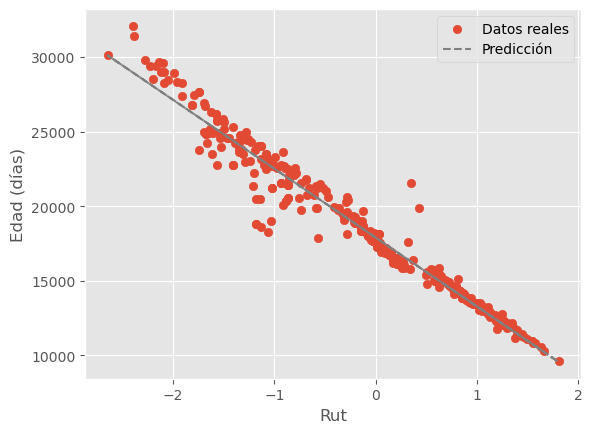

In [17]:
yhat_test = model_ann1.predict(X_test).ravel()

print('\nMétricas conjunto de test')
print(f'r2 = {r2_score(y_test, yhat_test)}')
print(f'RMSE(edad años) = {mean_squared_error(y_test, yhat_test, squared=False)/365}')
print()

plt.scatter(X_test, y_test, label='Datos reales')
plt.plot(X_test, yhat_test, ls='--', color='gray', lw=1.5, label='Predicción')
plt.xlabel('Rut')
plt.ylabel('Edad (días)')
plt.legend();

### <font color = 'green'>Prueba</font>
Vamos ahora a poner a prueba nuestro modelo, utilizando para ello el rut y fecha de nacimiento del Presidente Gabriel Boric:

- Fecha de nacimiento: 11-02-1986
- Rut: 16.163.631-2

In [18]:
rut2 = 16163631
fnac = '1986-02-11'


df_new = pd.DataFrame({'rut2': [rut2], 'fnac':[fnac]})
df_new['fnac'] = pd.to_datetime(df_new['fnac'], format='%Y-%m-%d')
df_new['edad_dias'] = (datetime.today() - df_new['fnac'][0]).days
df_new['edad_años'] = df_new['edad_dias']/365
df_new

,rut2,fnac,edad_dias,edad_años
0,16163631,1986-02-11,14128,38.706849


In [19]:
X_new = ss.transform(df_new.loc[:,['rut2', 'edad_dias']])[:,0]
model_ann1.predict(X_new)/365

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 92ms/step


array([[38.569782]], dtype=float32)

#<font color = 'green'>Implementación de una red neuronal</font>

Usaremos datos generados en forma aleatoria con separación lineal casi total, con cierto nivel de ruido. Nos enfrentamos a un problema de clasificación, con dos variables regresoras.

- np.argwhere(y==0) devuelve los índices de los puntos en X cuya etiqueta en y es 0.- 
.ravel() aplana el resultado de np.argwhere para obtener un array unidimensional
- 
X[np.argwhere(y==0).ravel()] selecciona los puntos en X correspondientes a la clase 0 y los almacena en X_cla0s
- .
X[np.argwhere(y==1).ravel()] hace lo mismo para la clase 1 y almacena los puntos en X_class1.

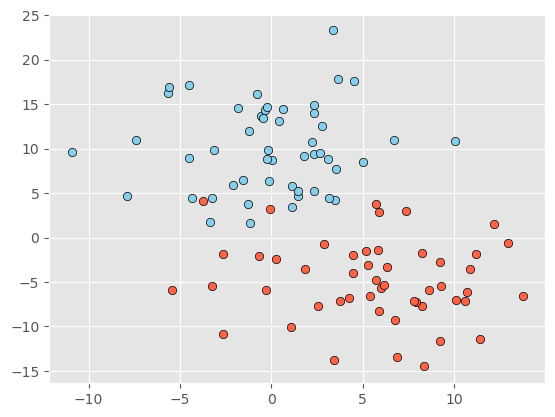

In [20]:
# Generar datos de ejemplo
X, y = make_blobs(n_samples=100, centers=2, random_state=23, cluster_std=4.5)

# El resultado es:
# X: Un array de forma (100, 2) con las coordenadas de los 100 puntos generados.
# y: Un array de etiquetas (0 o 1) que indica a qué clúster pertenece cada punto.

X_class0 = X[np.argwhere(y==0).ravel()]
X_class1 = X[np.argwhere(y==1).ravel()]


# plt.scatter es una función de Matplotlib que crea un gráfico de dispersión.
# X_class0[:,0], X_class0[:,1] selecciona las coordenadas de los puntos en la clase 0 (primera y segunda columna de X_class0).
# c='skyblue' colorea los puntos de la clase 0 de color azul cielo.
# marker='o' especifica que los puntos se dibujarán con el marcador circular.
# edgecolors='k' añade un borde negro ('k' para "black") alrededor de los puntos.


plt.scatter(X_class0[:,0], X_class0[:,1], c='skyblue', marker='o', edgecolors='k')
plt.scatter(X_class1[:,0], X_class1[:,1], c='tomato', marker='o', edgecolors='k');

##<font color = 'green'>Separación de los datos</font>

In [22]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.33, random_state=23)

##<font color = 'green'>Creación del modelo</font>
Creamos nuestro modelo de red neuronal usando sólo un Perceptrón

In [23]:
model_ann2 = Sequential()


# con 2 capas
model_ann2.add(keras.Input(shape=(2,)))

model_ann2.add(
    Dense(
        units=1,
        activation='sigmoid',
        use_bias=True
    )
)

model_ann2.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_1 (Dense)                      │ (None, 1)                   │               3 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 3 (12.00 B)

 Trainable params: 3 (12.00 B)

 Non-trainable params: 0 (0.00 B)

Compilamos nuestra red neuronal definiendo el optimizador (SGD) y la función de pérdida. y entrenamos la red usando 100 épocas.
Para problemas de clasificación binaria se recomienda usar función de pérdida la entropía cruzada.

In [24]:
# Stochastic Gradient Descent (SGD)

model_ann2.compile(optimizer=SGD(learning_rate=0.01), loss='binary_crossentropy')
model_ann2.fit(X_train, y_train, epochs=100, verbose=0)

Medimos las métricas asociadas a la matriz de confusión, para el conjunto de test

In [25]:
yhat = model_ann2.predict(X_test)
yhat = np.where(yhat < .5, 0, 1)

print(classification_report(y_test, yhat))

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step
              precision    recall  f1-score   support

           0       0.93      1.00      0.96        13
           1       1.00      0.95      0.97        20

    accuracy                           0.97        33
   macro avg       0.96      0.97      0.97        33
weighted avg       0.97      0.97      0.97        33



2813/2813 ━━━━━━━━━━━━━━━━━━━━ 8s 3ms/step


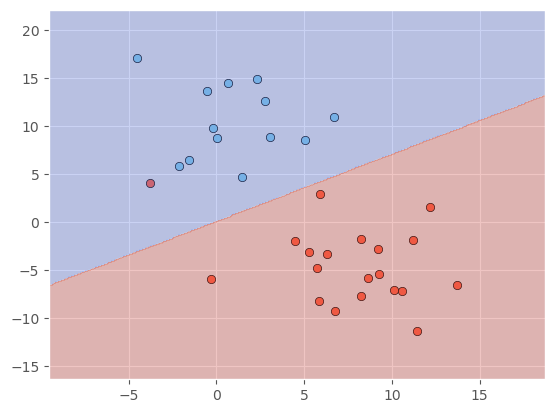

In [26]:
plot_region_classifier(X_test, y_test, model_ann2)

##<font color = 'green'>Red neuronal con perceptrón unicapa, para datos sin separación lineal</font>

- make_circles es una función de sklearn.datasets que genera un conjunto de datos bidimensional en forma de dos círculos concéntricos, ideal para problemas de clasificación no lineales.- 
n_samples=800 indica que se van a generar 800 puntos de datos
- 
noise=0.08 añade un poco de ruido aleatorio a los puntos, para que no estén perfectamente alineados en el círculo. Este parámetro controla la dispersión de los puntos alrededor del círcul
- .
factor=0.3 define la distancia entre los dos círculos concéntricos. Un valor más cercano a 1 significa que los círculos estarán más próxim s, mientras que un valor más pequeño los separa más. Aquí, el círculo interno es mucho más pequeño (30% del tamaño del círculo exte ).
- ).
random_state=23 asegura que la generación de datos sea reproducible, es decir, si se ejecuta el código otra vez, los datos generados serán los mis


El resultado es:
-   X: Un array de forma (800, 2) que contiene las coordenadas de los puntos generados en dos dimensiones (X1, X2
-    y: Un array con las etiquetas de clase (0 o 1), donde los puntos etiquetados con 0 pertenecen al círculo exterior, y los puntos etiquetados co  1 pertenecen al círculo interior.mos.

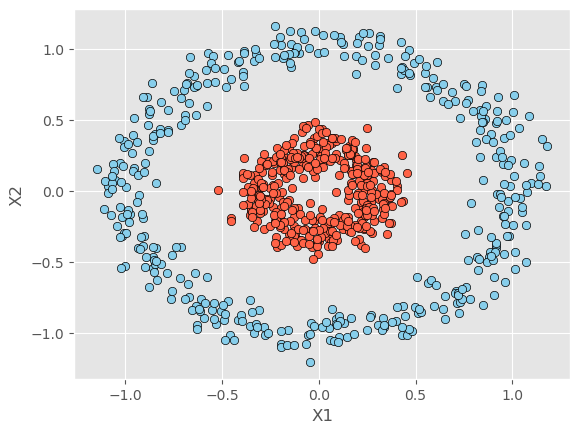

In [28]:
X, y = make_circles(n_samples=800, noise=0.08, factor=0.3, random_state=23)

idx_class0 = np.argwhere(y==0).ravel()
idx_class1 = np.argwhere(y==1).ravel()

plt.scatter(X[idx_class0,0], X[idx_class0,1], c='skyblue', marker='o', edgecolors='k') # clase 0 | circulo exterior
plt.scatter(X[idx_class1,0], X[idx_class1,1], c='tomato', marker='o', edgecolors='k') # clase 1 | circulo interior
plt.xlabel('X1')
plt.ylabel('X2');

##<font color = 'green'>Separación de los datos</font>

In [29]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.33, random_state=23)

##<font color = 'green'>Creación de la arquitectura</font>
Creamos la arquitectura de la red neuronal con sólo un Perceptrón

In [30]:
model_ann3 = Sequential()


## con 2 capas
model_ann3.add(keras.Input(shape=(2,)))
model_ann3.add(
    Dense(
        units=1,
        activation='sigmoid',
        use_bias=True
    )
)

model_ann3.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                      │ (None, 1)                   │               3 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 3 (12.00 B)

 Trainable params: 3 (12.00 B)

 Non-trainable params: 0 (0.00 B)

Se compila el modelo de red neuronal y se entrena con los datos de entrenamiento. Se usan 100 épocas.

In [31]:
# Stochastic Gradient Descent (SGD)

model_ann3.compile(optimizer=SGD(learning_rate=0.01), loss='binary_crossentropy')
model_ann3.fit(X_train, y_train, epochs=100, verbose=0)

2813/2813 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step


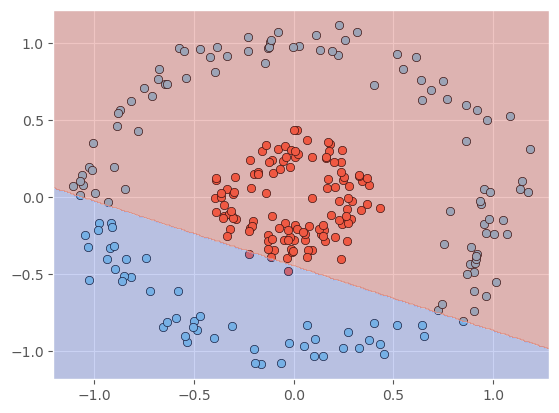

In [32]:
plot_region_classifier(X_test, y_test, model_ann3, pad=0.1)

##<font color = 'green'>Utilizando una capa oculta</font>
Se agrega una capa oculta a nuestra red con 15 neuronas, usando función de activación Relu en la capa oculta.

In [33]:
model_ann4 = Sequential()

model_ann4.add(keras.Input(shape=(2,)))
model_ann4.add(
    Dense(
        units=15,
        activation='relu',
        use_bias=True
    )
)

model_ann4.add(
    Dense(
        units=1,
        activation='sigmoid',
        use_bias=True
    )
)

model_ann4.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                      │ (None, 15)                  │              45 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 1)                   │              16 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 61 (244.00 B)

 Trainable params: 61 (244.00 B)

 Non-trainable params: 0 (0.00 B)

Entrenamos y compilamos nuestra red neuronal para 100 épocas

In [34]:
model_ann4.compile(optimizer=SGD(learning_rate=0.01), loss='binary_crossentropy')
model_ann4.fit(X_train, y_train, epochs=100, verbose=0)

2813/2813 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step


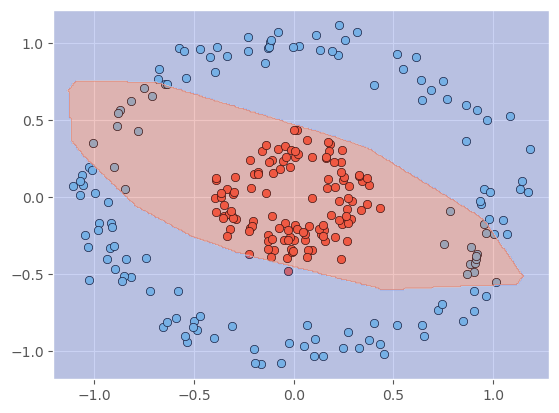

In [35]:
plot_region_classifier(X_test, y_test, model_ann4, pad=0.1)